# Passenger Panel Detector — Fine-Tuning YOLOv8s

**Author:** Zidane Taufiqul Hakim
**Date:** 13 August 2026
**Project:** [Train Traffic Capture](../README.md)

This notebook builds the object detector at the front of the Train Traffic
Capture pipeline. The detector looks at a screenshot of a train-simulator
station panel and finds five kinds of text region. Later stages read those
regions with OCR and turn them into a table of passenger events.

**Goal:** fine-tune a COCO-pretrained YOLOv8s model to detect and classify the
five classes below with mAP@0.5 ≥ 0.85, missing as few regions as possible.

| ID | Class | Region |
|---|---|---|
| 0 | `passenger_increse` | Passenger count at the start of a row (`3 pax`) |
| 1 | `station_id` | Bracketed station code (`[BD108]`) |
| 2 | `station_name` | Station name (`Hasan Sadikin`) |
| 3 | `station_numbering` | Parenthesised number (`(4-13)`) |
| 4 | `time` | In-game clock in the top toolbar |

> `passenger_increse` is misspelled, and the spelling is kept on purpose: it is
> the class name stored in the trained weights, so everything downstream uses it.

## Contents

1. [Setup](#1.-Setup)
2. [Data preparation](#2.-Data-preparation) — inspection, augmentation, split
3. [Training](#3.-Training)
4. [Evaluation](#4.-Evaluation)
5. [Summary](#5.-Summary)
6. [Known limitations and next steps](#6.-Known-limitations-and-next-steps)

**About the outputs.** Cells were run over several sessions and are shown with
the outputs recorded at the time. Absolute paths are shortened to `<project>`,
and the training log is condensed. Where a recorded output no longer matches
the final dataset, a note says so.

## 1. Setup

In [ ]:
# Data Handling
import pandas as pd
import os
import numpy as np
from collections import Counter
from pathlib import Path

# Image Processing
from PIL import Image, ImageDraw

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sn

# Training Tools
from ultralytics import YOLO
import torch
import cv2
import shutil
import random
import albumentations as A


In [ ]:
# Environment Check
print(f"PyTorch Version  : {torch.__version__}")
print(f"MPS (Mac GPU)    : {torch.backends.mps.is_available()}")
print(f"CUDA (Nvidia)    : {torch.cuda.is_available()}")

PyTorch Version  : 2.13.0
MPS (Mac GPU)    : True
CUDA (Nvidia)    : False


Library versions used:

| Library | Version |
|---|---|
| Python | 3.10.20 |
| ultralytics | 8.4.118 |
| torch | 2.13.0 |
| opencv-python | 5.0.0 |
| pandas | 2.3.3 |
| numpy | 2.2.5 |
| Pillow | 12.3.0 |
| matplotlib | 3.10.9 |
| seaborn | 0.13.2 |

## 2. Data preparation

The source images are screenshots of the simulator with a station panel open,
labelled in Label Studio and exported in YOLO format to
`data/annotated_dataset/` (`images/` and `labels/`).

### 2.1 Inspection

Before training, count the images and the labelled instances of each class.
Instance counts matter more than image counts here: one screenshot contains
several rows but only one clock.

In [ ]:
class DatasetInspector:
    def __init__(self, img_dir:str, labels_dir:str):
        self.img_dir = img_dir
        self.labels_dir = labels_dir

    def count_total_samples(self) -> dict:
        "count total samples"
        img_path = Path(self.img_dir)

        if not img_path.exists():
            print(f"Path does not exist: {img_path}")
            return {"total_images_samples": 0}
            
        image_files = [f for f in img_path.glob("**/*") if f.is_file()]

        return {"total_images_samples": len(image_files)}

    def count_classes(self, class_names: dict) -> pd.DataFrame:
        """Aggregates class instance counts across all .txt files in a directory."""
        labels_path = Path(self.labels_dir)
        txt_files = list(labels_path.glob("**/*.txt"))
        
        total_counts = Counter()
    
        for txt_file in txt_files:
            with open(txt_file, 'r') as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        cls_id = int(parts[0])
                        total_counts[cls_id] += 1
    
        df_summary = pd.DataFrame([
            {
                "Class ID": cid,
                "Class Name": name,
                "Total Instances": total_counts.get(cid, 0)
            }
            for cid, name in class_names.items()
        ])

        return df_summary

In [ ]:
inspector = DatasetInspector(
    img_dir='../data/annotated_dataset/images',
    labels_dir='../data/annotated_dataset/labels'
)

labels_map= {
    0:'passenger_increse',
    1:'station_id',
    2:'station_name',
    3:'station_numbering',
    4:'time'
}
total_samples = inspector.count_total_samples()
classes_counts = inspector.count_classes(class_names=labels_map)

In [ ]:
print("===TOTAL IMAGES SAMPLES===")
print(f'{total_samples}\n')
print("===COUNTS PER CLASS===")
print(classes_counts)
print(f"SUM of Total Instances per Class:{np.sum(list(instance for instance in classes_counts['Total Instances']))}")

===TOTAL IMAGES SAMPLES===
{'total_images_samples': 62}

===COUNTS PER CLASS===
   Class ID         Class Name  Total Instances
0         0  passenger_increse              245
1         1         station_id              253
2         2       station_name              253
3         3  station_numbering              223
4         4               time               39
SUM of Total Instances per Class:1013


**Finding.** `time` is under-represented: 39 instances against roughly 220–250 for each of the
other classes, because each frame has one clock but several rows.
Undersampling the other classes would throw away scarce data, so the imbalance
is left as it is. The risk is that the model under-learns `time` and labels real
clocks as something else; if evaluation shows that, the fix is to collect more
screenshots rather than rebalance. (It did not — see section 4.)

The folder already held 62 images at this point: 32 labelled screenshots plus
30 files from an earlier run of the augmentation step below.

### 2.2 Offline augmentation

Real recordings differ from these screenshots in resolution, compression and
brightness. Augmentation exposes the model to those differences so it does not
depend on pixel-exact appearance. Each transform is applied to a share of the
images, sized by how likely that variation is in practice:

| Transform | Share | Reasoning |
|---|---|---|
| Brightness / contrast jitter | 35% | Highest-value transform: recording software, display settings and in-game brightness all vary |
| Scale jitter (+5–10%) | 25% | Different recording resolutions and window sizes |
| JPEG compression noise | 20% | Compressed recordings, such as YouTube re-uploads |
| Minor translation (±3%) | 15% | Avoids overfitting to exact pixel positions |
| Gaussian noise | 5% | A small dose, so the model does not rely on perfectly sharp edges |

Rotation, flips and mosaic are deliberately absent: UI text is always upright
and axis-aligned.

The function writes the augmented copies back into the dataset folder, each
with a copy of its source image's label file.

In [ ]:
def augment_dataset_inplace(img_dir, txt_dir, aug_config):
    img_path_obj = Path(img_dir)
    txt_path_obj = Path(txt_dir)
    
    # Ensure directories exist before reading
    if not img_path_obj.exists():
        raise FileNotFoundError(f"Directory not found: {img_path_obj}")

    image_files = [f for f in os.listdir(img_path_obj) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]
    staging_data = []

    # STEP 1: Process each portion into staging buffer
    for transform, portion in aug_config.items():
        sample_size = int(len(image_files) * portion)
        sampled_files = random.sample(image_files, sample_size)
        
        for img_name in sampled_files:
            base_name, ext = os.path.splitext(img_name)
            txt_name = f"{base_name}.txt"
            
            file_img_path = img_path_obj / img_name
            file_txt_path = txt_path_obj / txt_name
            
            image = cv2.imread(str(file_img_path))
            if image is None:
                continue  # Skip unreadable images safely
                
            label_content = ""
            if file_txt_path.exists():
                with open(file_txt_path, 'r') as f:
                    label_content = f.read()
            
            # Apply transformation
            augmented = transform(image=image)
            aug_image = augmented['image']
            
            aug_base_name = f"{base_name}_aug_{random.randint(10000, 99999)}"
            
            staging_data.append({
                "dest_img_name": f"{aug_base_name}{ext}",
                "dest_txt_name": f"{aug_base_name}.txt",
                "image": aug_image,
                "label": label_content
            })

    # STEP 2: Shuffle staging data
    random.shuffle(staging_data)

    # STEP 3: Write augmented files into absolute target directories
    for item in staging_data:
        dest_img_path = img_path_obj / item["dest_img_name"]
        dest_txt_path = txt_path_obj / item["dest_txt_name"]
        
        cv2.imwrite(str(dest_img_path), item["image"])
        with open(dest_txt_path, 'w') as f:
            f.write(item["label"])

    print(f"Target Image Folder: {img_path_obj}")
    print(f"Added {len(staging_data)} new augmented files directly into your dataset folder.")

In [ ]:
#Dynamically find the absolute path to your notebook directory
NOTEBOOK_DIR = Path.cwd() 

#Build absolute paths relative to your notebook location
IMG_DIR = (NOTEBOOK_DIR / "../data/annotated_dataset/images").resolve()
TXT_DIR = (NOTEBOOK_DIR / "../data/annotated_dataset/labels").resolve()

# Directly defined Python dictionary mapping transforms to sample percentages
aug_config = {
    A.ColorJitter(brightness=0.2, contrast=0.2, p=1.0): 0.35,              # 35% Brightness/contrast jitter
    A.RandomScale(scale_limit=(0.05, 0.10), p=1.0): 0.25,                  # 25% Scale jitter (±5-10%)
    A.ImageCompression(quality_range=(60, 90), p=1.0): 0.20,              # 20% JPEG/compression noise
    A.Affine(translate_percent=(-0.03, 0.03), p=1.0): 0.15,               # 15% Minor translation (few px)
    A.GaussNoise(var_limit=(10.0, 50.0), p=1.0): 0.05                      # 5% Slight Gaussian noise
}

# Execution call
augment_dataset_inplace(IMG_DIR, TXT_DIR, aug_config)

<ipython-input>:14: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=1.0): 0.05                      # 5% Slight Gaussian noise


Target Image Folder: <project>/data/annotated_dataset/images
Added 60 new augmented files directly into your dataset folder.


Two things to know about this step:

- **The Gaussian-noise setting was ignored.** The warning above shows that the
  installed Albumentations version does not accept `var_limit`, so that
  transform ran with its default noise level.
- **Labels are copied unchanged.** That is correct for the colour, compression
  and noise transforms, and for scaling (YOLO coordinates are relative). It is
  not correct for translation, where the boxes end up offset from the text by up
  to 3% of the image size. See section 6.

In [ ]:
total_samples = inspector.count_total_samples()
classes_counts = inspector.count_classes(class_names=labels_map)

print("===TOTAL IMAGES SAMPLES (AUG)===")
print(f'{total_samples}\n')
print("===COUNTS PER CLASS(AUG)===")
print(classes_counts)
print(f"SUM of Total Instances per Class:{np.sum(list(instance for instance in classes_counts['Total Instances']))}")

===TOTAL IMAGES SAMPLES (AUG)===
{'total_images_samples': 122}

===COUNTS PER CLASS(AUG)===
   Class ID         Class Name  Total Instances
0         0  passenger_increse              463
1         1         station_id              468
2         2       station_name              468
3         3  station_numbering              424
4         4               time               73
SUM of Total Instances per Class:1896


### 2.3 Train / validation split

A random 80/20 split of the augmented folder into YOLO's `train/` and `val/`
layout.

In [ ]:
def train_val_split(img_dir, txt_dir, output_dir, val_split=0.2, shuffle=True):
    """Splits image and label directory into YOLO-style train/val folders."""
    img_path, txt_path, out_path = Path(img_dir).resolve(), Path(txt_dir).resolve(), Path(output_dir).resolve()
    
    # 1. Gather images and shuffle
    images = [f for f in img_path.iterdir() if f.suffix.lower() in ('.jpg', '.png', '.jpeg')]
    if shuffle:
        random.shuffle(images)
    
    # 2. Split into train and val lists
    val_count = int(len(images) * val_split)
    split_map = {'val': images[:val_count], 'train': images[val_count:]}
    
    # 3. Copy files to target directories
    for split, files in split_map.items():
        dest_img_dir = out_path / split / "images"
        dest_txt_dir = out_path / split / "labels"
        dest_img_dir.mkdir(parents=True, exist_ok=True)
        dest_txt_dir.mkdir(parents=True, exist_ok=True)
        
        for img in files:
            shutil.copy(img, dest_img_dir / img.name)
            
            txt_file = txt_path / f"{img.stem}.txt"
            if txt_file.exists():
                shutil.copy(txt_file, dest_txt_dir / txt_file.name)

    print(f"Done! Saved {len(split_map['train'])} train and {len(split_map['val'])} val samples to {out_path}")
    

In [ ]:
img_dir = '../data/annotated_dataset/images'
labels_dir = '../data/annotated_dataset/labels'
output_dir = '../data'
train_val_split(img_dir,labels_dir,output_dir,val_split=0.2)

Done! Saved 98 train and 24 val samples to <project>/data


Per-class instance counts in each split:

In [ ]:
to_be_inspected = {
    'train': ('../data/train/images', '../data/train/labels'),
    'val': ('../data/val/images', '../data/val/labels')
}

labels_map = {
    0: 'passenger_increse',
    1: 'station_id',
    2: 'station_name',
    3: 'station_numbering',
    4: 'time'
}

all_series = []

for split_name, (img_dir, labels_dir) in to_be_inspected.items():
    inspector = DatasetInspector(
        img_dir=Path(img_dir).resolve(),
        labels_dir=Path(labels_dir).resolve()
    )
    
    classes_counts = inspector.count_classes(class_names=labels_map)
    
    # If classes_counts is a DataFrame, set 'Class Name' as index and extract counts
    if isinstance(classes_counts, pd.DataFrame):
        counts_series = classes_counts.set_index('Class Name')['Total Instances']
    else:
        counts_series = pd.Series(classes_counts)
        
    counts_series.name = split_name
    all_series.append(counts_series)

# Combine into a clean side-by-side comparative table
df = pd.concat(all_series, axis=1).T.fillna(0).astype(int)
print(df)

> **Note on the recorded outputs.** The split shown above (98 / 24) is from an
> earlier pass. The dataset the model was finally trained on is
> `data/cleaned_dataset/`, with **110 training and 34 validation images**
> (1,741 and 531 labelled instances) — the figures that appear in the training
> log in section 3. The output of the per-split count cell was not preserved.

### 2.4 Dataset configuration

YOLO reads the dataset location and class names from a YAML file.

In [ ]:
from pathlib import Path
import yaml

# Define target paths
base_dir = Path("../data/cleaned_dataset").resolve()

# Configuration layout required by YOLO
yaml_data = {
    'path': str(base_dir),
    'train': 'train/images',
    'val': 'val/images',
    'names': {
        0: 'passenger_increse',
        1: 'station_id',
        2: 'station_name',
        3: 'station_numbering',
        4: 'time'
    }
}

# Write dataset.yaml file
yaml_file_path = base_dir / "dataset.yaml"
with open(yaml_file_path, 'w') as f:
    yaml.dump(yaml_data, f, default_flow_style=False, sort_keys=False)

print(f"Generated YAML file at: {yaml_file_path}")

Generated YAML file at: <project>/data/cleaned_dataset/dataset.yaml


## 3. Training

Fine-tuning starts from `yolov8s.pt`, pretrained on COCO. No public model knows
these classes, but pretrained low-level features — edges, corners, strokes —
transfer well, which is what makes training on about a hundred images feasible.

| Setting | Why |
|---|---|
| `freeze=10` | Freezes the backbone so only the neck and head train. With so few images this is the main guard against memorising the training set. |
| `lr0=0.001`, `cos_lr`, `warmup_epochs=3` | A gentle learning rate with warm-up protects the pretrained weights; cosine decay lets the head settle. With `optimizer="auto"`, Ultralytics chooses AdamW and sets the rate itself (≈0.0011 here). |
| `epochs=180`, `patience=25` | An upper bound with early stopping. |
| `mosaic`, `mixup`, `copy_paste` = 0 | These stitch or blend images, which would break rows apart into layouts the UI never produces. |
| flips, rotation, shear, perspective = 0 | The UI is always upright and axis-aligned; mirrored text does not occur. |
| `hsv_h=0` | Hue is fixed by the game's theme. |
| `hsv_s`, `hsv_v`, `translate`, `scale` (small) | Mild versions of variation that does occur: brightness, panel position, window size. |
| `seed=42`, `deterministic=True` | Reproducible runs. |

Training ran on an Apple M1 GPU (`device="mps"`) and took 1.6 hours.

In [ ]:
# 1. Path to your generated dataset.yaml
yaml_path = Path("../data/cleaned_dataset/dataset.yaml").resolve()

# 2. Load pre-trained base model
model = YOLO("yolov8s.pt")

# 3. Train using your exact training recipe
results = model.train(
    # Core Setup
    data=str(yaml_path),
    epochs=180,
    patience=25,
    batch=16,
    imgsz=640,
    device="mps",
    workers=4,
    freeze=10,             # Freeze backbone (first 10 layers)
    
    # Optimization & Learning Rate
    optimizer="auto",      # Defaults to AdamW for small datasets
    lr0=0.001,             # Gentle learning rate for fine-tuning
    cos_lr=True,           # Cosine learning rate scheduler
    warmup_epochs=3,
    
    # Disabled Augmentations (Preserves UI/Spatial/Text Context)
    mosaic=0.0,
    mixup=0.0,
    fliplr=0.0,
    flipud=0.0,
    degrees=0.0,
    shear=0.0,
    perspective=0.0,
    copy_paste=0.0,
    hsv_h=0.0,
    
    # Active Augmentations (Safe for Capture UI)
    hsv_s=0.15,
    hsv_v=0.2,
    translate=0.05,
    scale=0.15,
    
    # Checkpoints & Reproducibility
    save_period=10,
    seed=42,
    deterministic=True,
    
    # Project Logging
    project="train_passenger_capture",
    name="yolov8s_mps_run"
)

# 4. Print validation summary metrics
print("\n--- Training Complete ---")
print(f"mAP@0.5: {results.box.map50:.4f}")
print(f"mAP@0.5:0.95: {results.box.map:.4f}")

# Check success threshold
if results.box.map50 >= 0.85:
    print(" SUCCESS: Met target threshold (mAP@0.5 >= 0.85)!")
else:
    print(" WARNING: Failed to reach target mAP@0.5 (0.85). Consider dropping freeze to 5 or 0.")

Ultralytics 8.4.118 🚀 Python-3.10.20 torch-2.13.0 MPS (Apple M1)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=<project>/data/cleaned_dataset/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=180, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.0, hsv_s=0.15, hsv_v=0.2, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=yolov8s_mps_run, nbs=64, nms=False, 

## 4. Evaluation

### 4.1 Final metrics

The last block of the training log validates `best.pt` — the weights shipped
with the application — on the 34-image validation split:

| Class | Instances | Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|---|---|
| **all** | 531 | 0.936 | 0.883 | **0.948** | 0.769 |
| `passenger_increse` | 117 | 0.944 | 0.857 | 0.958 | 0.729 |
| `station_id` | 137 | 0.929 | 0.859 | 0.958 | 0.787 |
| `station_name` | 137 | 0.945 | 0.869 | 0.918 | 0.722 |
| `station_numbering` | 120 | 0.941 | 0.883 | 0.916 | 0.751 |
| `time` | 20 | 0.921 | 0.950 | 0.988 | 0.856 |

mAP@0.5 is 0.948, above the 0.85 target. `time`, the class with the fewest
examples, scores highest, so the imbalance noted in section 2.1 did not hurt.

For comparison, a separate training run (`yolov8s_mps_run-5`, evaluated on 27
images) gave the result below. The curves and commentary in 4.2–4.4 were
written against that run; its numbers differ slightly but the pattern is the same.

```
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)
                   all         27        252      0.942      0.947      0.968      0.734
     passenger_increse         10         54      0.931      0.963      0.986      0.696
            station_id         11         63      0.968      0.955      0.992      0.742
          station_name         11         63      0.909      0.873      0.925      0.625
     station_numbering         14         52      0.917      0.942      0.942      0.684
                  time         20         20      0.982          1      0.995      0.924
```

### 4.2 Training history

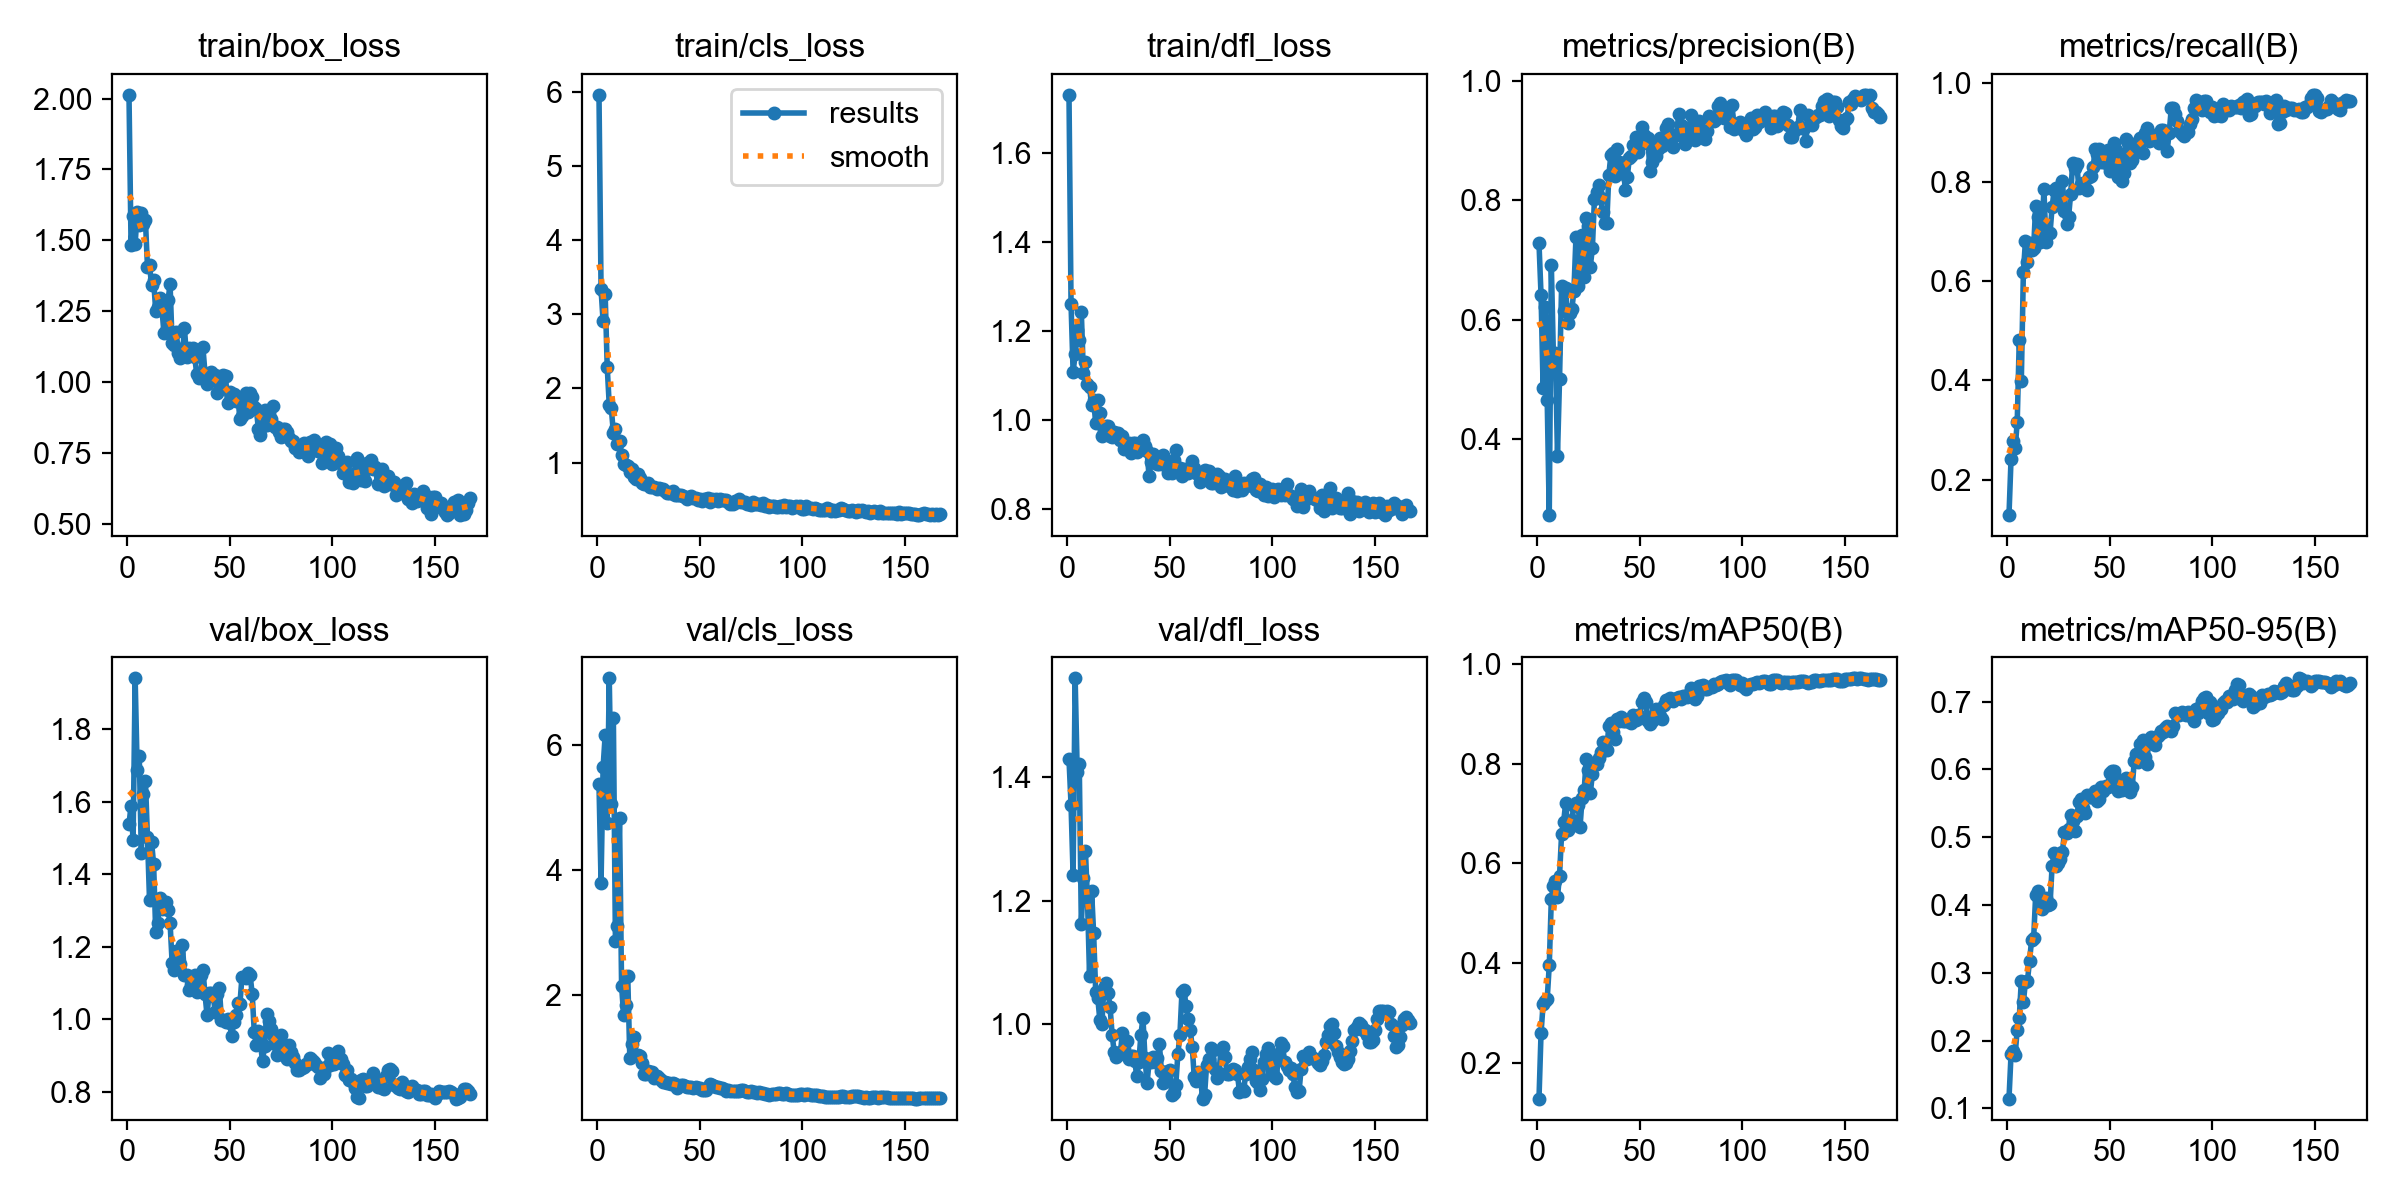

Box, classification and DFL losses fall together on the training and validation
sets, which indicates the model is learning the features rather than
memorising, even though `station_numbering` and `time` have fewer examples.
`freeze=10` is the likely reason: with the backbone fixed, the model has less
capacity to memorise a small dataset.

The validation DFL loss is noisy because the validation set is small, so each
value averages over few boxes. It rises slightly after about epoch 100 while
mAP@0.5 and mAP@0.5:0.95 keep climbing, so this is not treated as overfitting.

### 4.3 Precision–recall curve

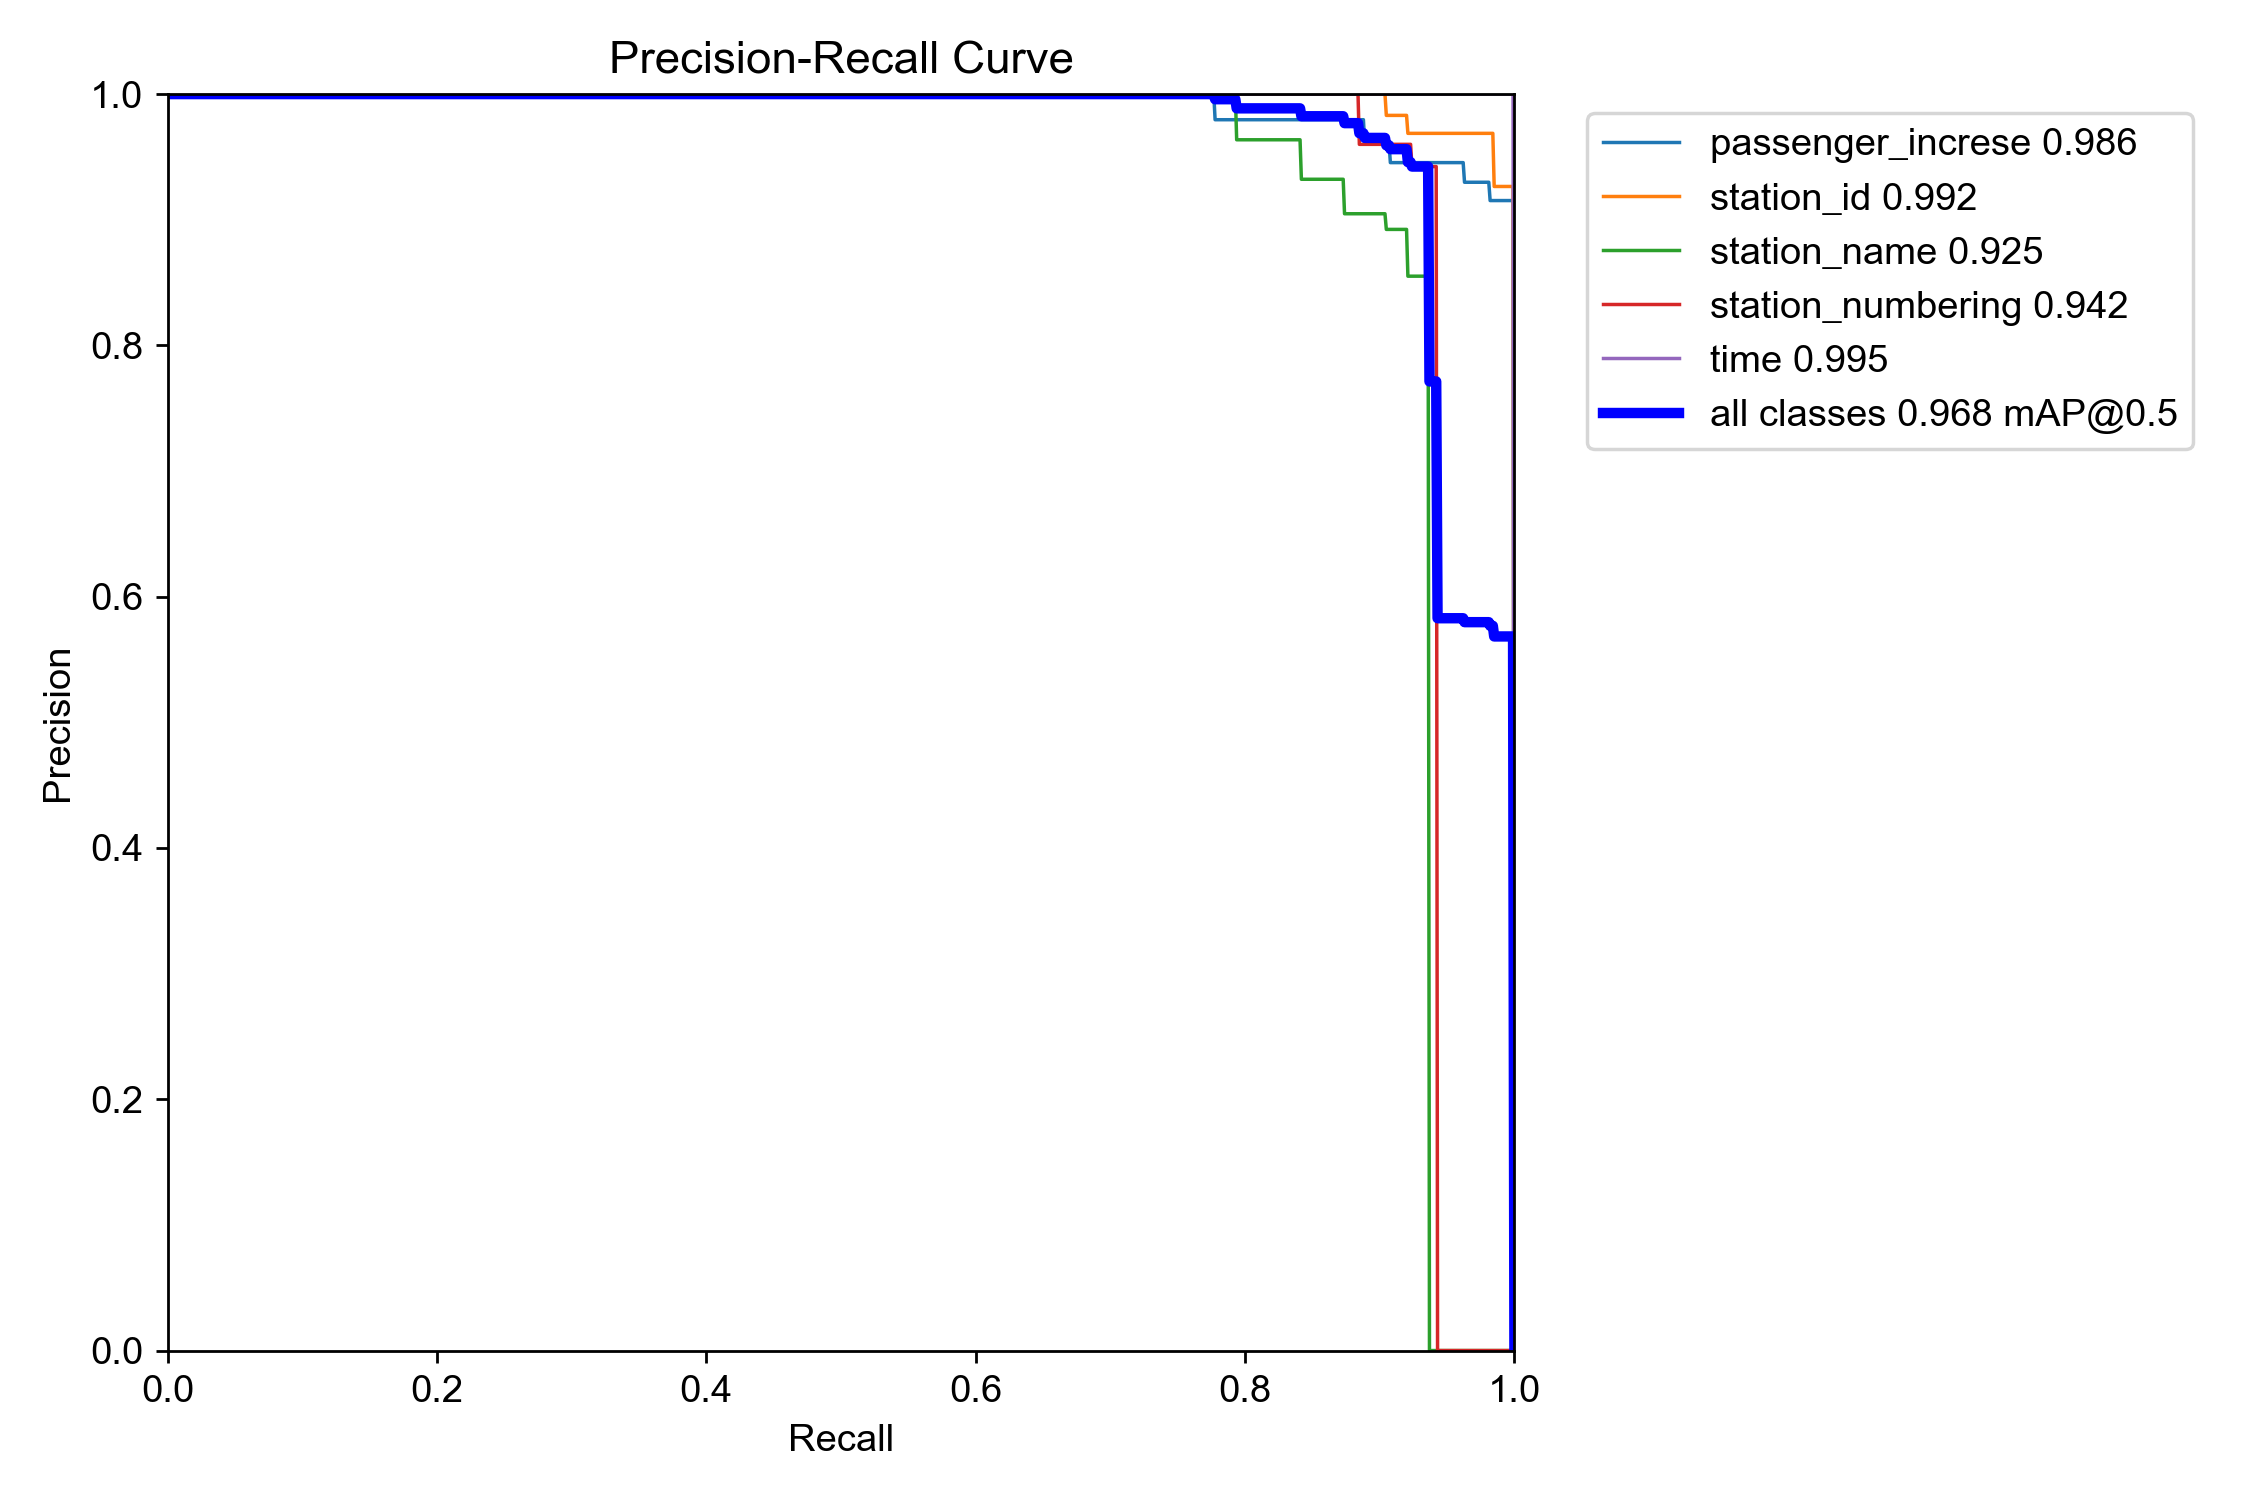

A high mAP@0.5 means the model rarely mistakes one class for another. The
mAP@0.5:0.95 score of roughly 0.73–0.77 shows the boxes are also reasonably
tight around the text, which matters because OCR reads directly from these crops.

### 4.4 Recall curve

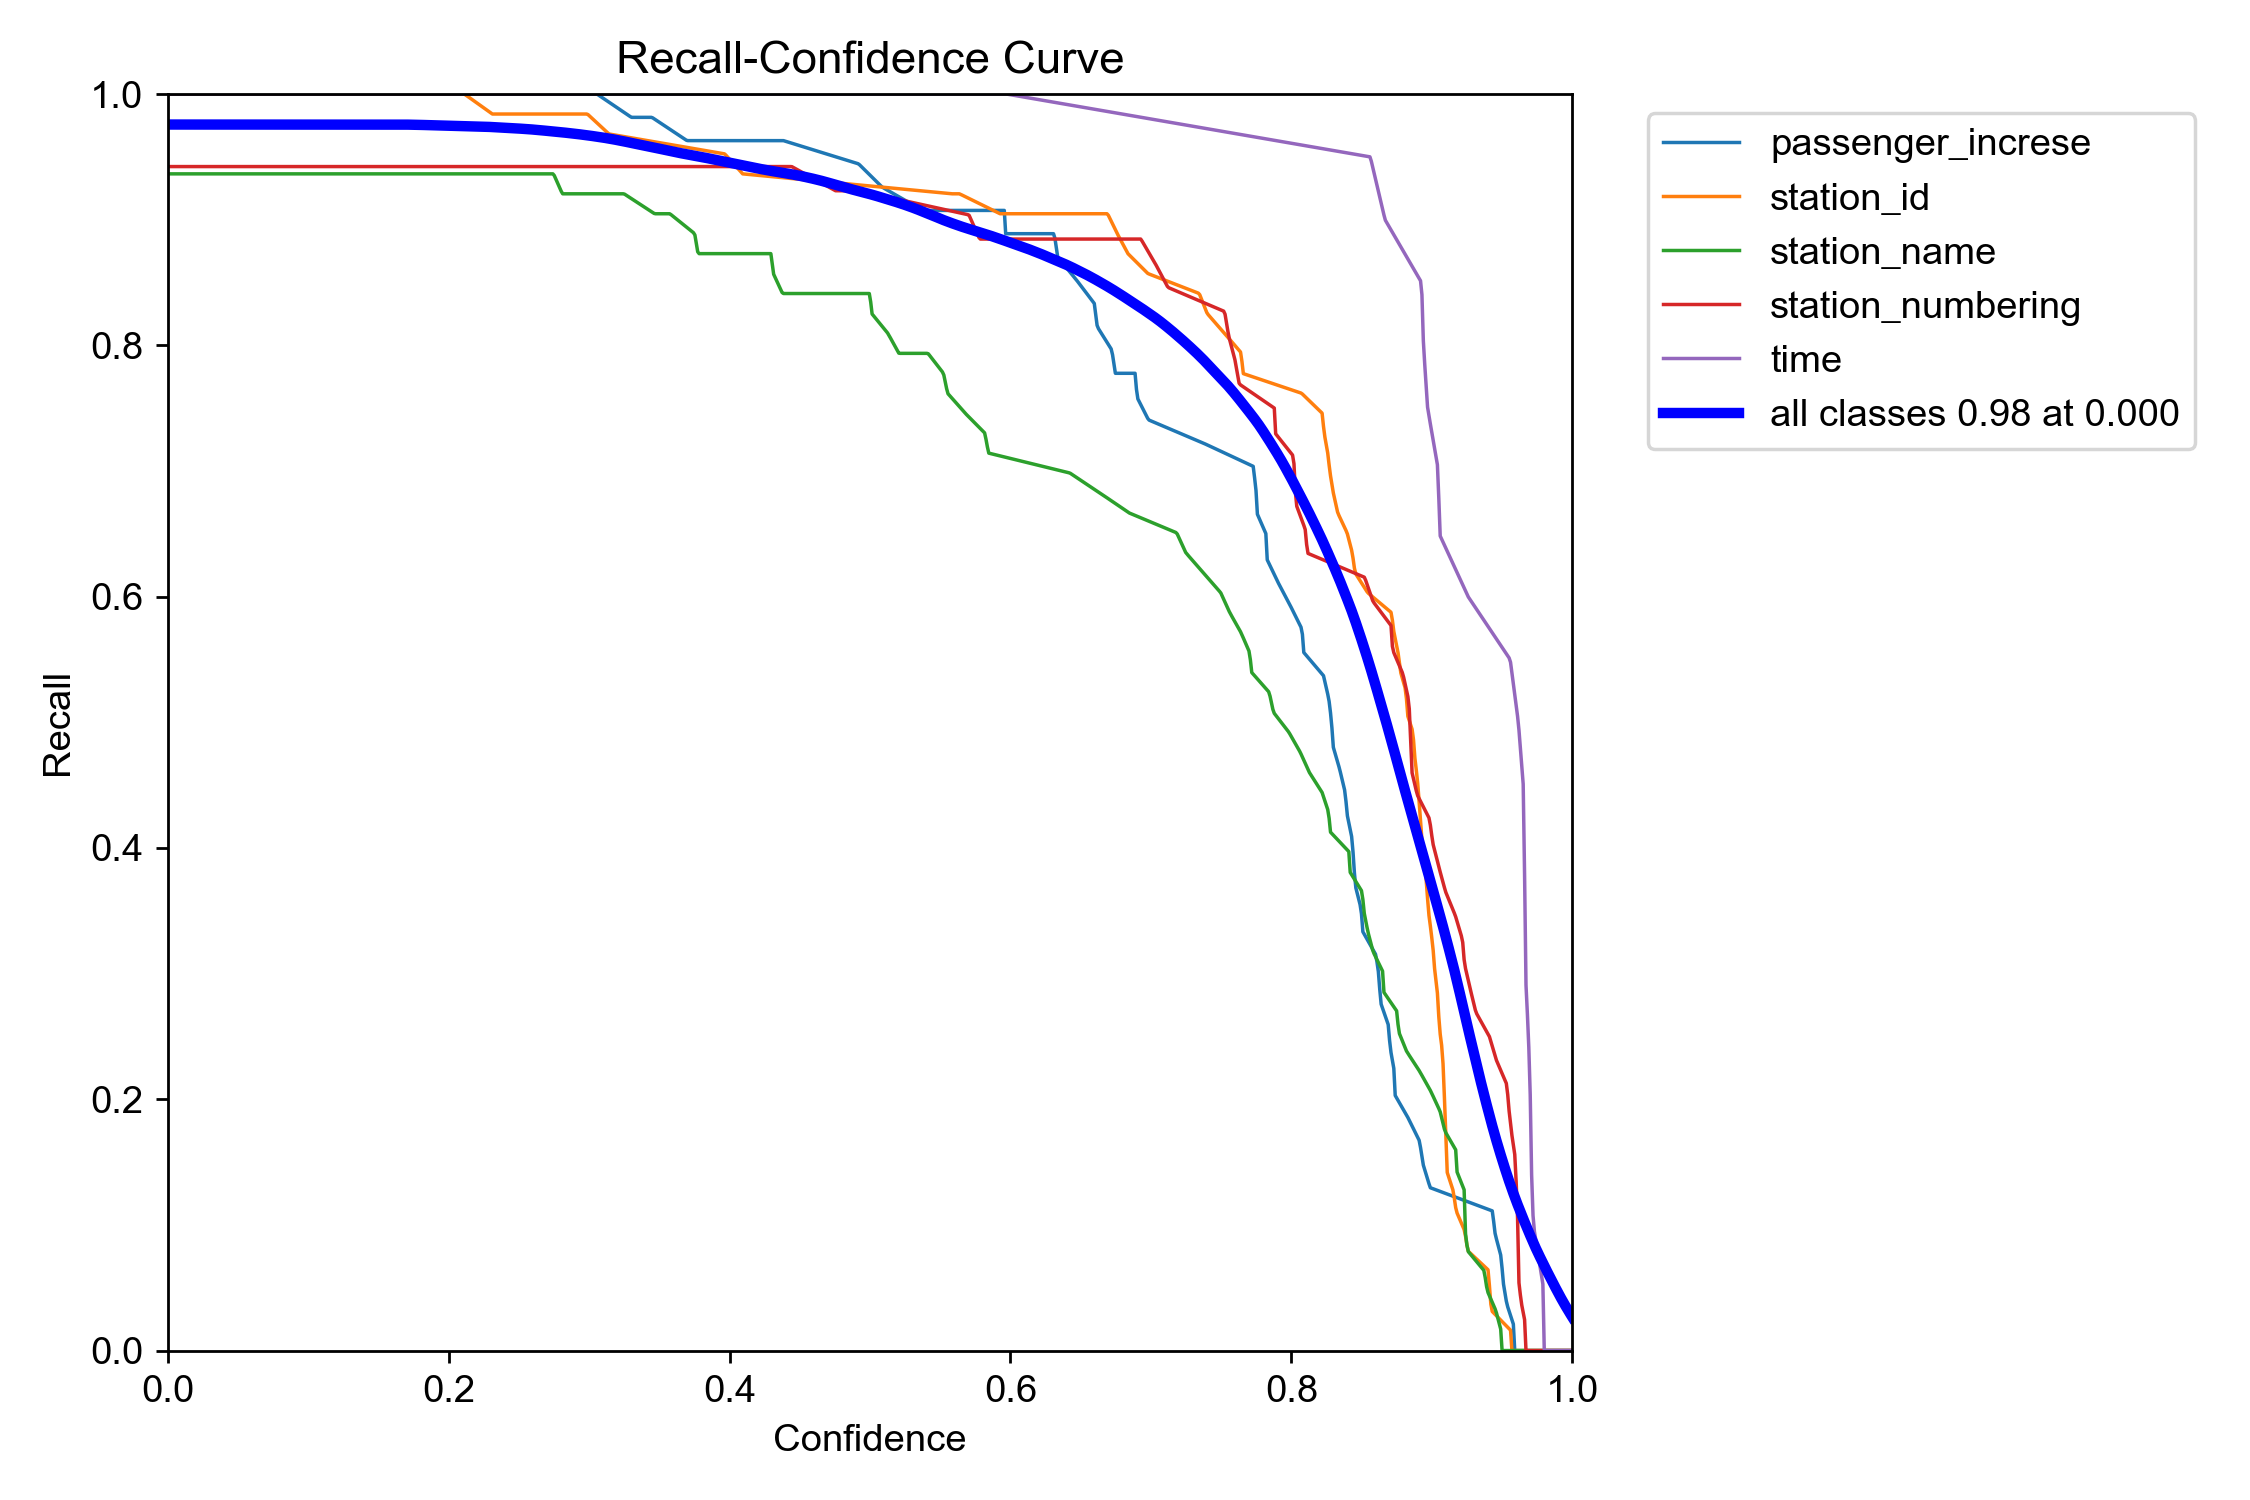

This is the main concern. `station_name` sits below the average recall curve:
in this run its recall was 0.873 while every other class was above 0.94. At
that rate, roughly 127 of every 1,000 station names would go undetected and
appear as missing values in the output.

## 5. Summary

**Model:** YOLOv8s, COCO-pretrained, `freeze=10`, fine-tuned for five classes of UI text.

### Strengths

- **Stable training without overfitting.** Training and validation losses
  converge together, and validation mAP rises throughout.
- **`freeze=10` works as regularisation.** Limiting training to the neck and
  head is probably the main reason a dataset this small did not overfit.
- **Strong overall detection.** mAP@0.5 of 0.948 for the shipped weights, well
  above the 0.85 target.
- **Good localisation.** mAP@0.5:0.95 of 0.77 means boxes are tight enough for
  OCR to read from the crops.

### Weaknesses

- **`station_name` is the weak class** on the precision–recall and recall
  curves. The likely cause is variable length: station names differ far more in
  character count than codes, numbers or times. This looks like a data-coverage
  gap rather than a limit of the model.
- **The precision–recall trade-off is sharpest for `station_name`.** Removing
  nearly all false positives needs a confidence threshold of 0.6–0.7, where
  recall falls to 0.6–0.7.
- **Validation loss is noisy** because the validation set is small. mAP trends
  are the more reliable signal.

### Decision

Rather than collect more data to improve a field whose value is already implied
by another, the application does not read `station_name` at all. The station
code is read and the name is looked up from a table of known stations
(`STATION_LOOKUP` in `application/config.py`). `station_numbering` is not read
either. Both classes stay in the model so that those regions are recognised for
what they are instead of being mislabelled as something else.

## 6. Known limitations and next steps

1. **Validation overlaps training.** The split is made per image, after
   augmentation, so augmented copies of one screenshot land on both sides. In
   the final dataset every source screenshot in the validation split also
   appears in the training split. The scores above therefore overstate accuracy
   on unseen recordings.
2. **Translated images have offset labels** (section 2.2).
3. **Small source set.** Everything derives from 32 labelled screenshots of one
   network at one display resolution.
4. **Not fully reproducible from this notebook.** The split cell writes to
   `data/train` and `data/val`, while training reads `data/cleaned_dataset`.

For the next training round:

- Split by source screenshot *before* augmenting, and augment the training split only.
- Apply geometric transforms with Albumentations' `bbox_params` so labels move with the image.
- Hold out a complete recording session as a test set.
- Add screenshots with long and unusual station names.

The trained weights are copied to `model_registry/passenger_capture_yolov8s.pt`
for the application. See [Data and training](../docs/data-and-training.md) for
the written-up version of this notebook and [Pipeline](../docs/pipeline.md) for
how the detector is used.